<a href="https://colab.research.google.com/github/icy-agarwal/churn-predictor-cost-sensitive/blob/main/churn_predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Predictor with a Cost-Sensitive Offer Threshold

Data: Amazon Review Data (2018), Musical Instruments, 5-core file (UCSD).

**Definition:** among customers with a review in the 365 days before a cutoff date, churn means no review in the 180 days after it. Reviews stand in for purchase activity.

**All rupee figures in this notebook are assumptions, not real business data.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, confusion_matrix
from xgboost import XGBClassifier

## 1. Data

The download uses a temporary file, so a failed download cannot overwrite a good copy. If the UCSD server is unreachable, download the file in a browser from the same link, upload it to this notebook and name it `musical_instruments.json.gz`.

In [2]:
!wget -O tmp_download.json.gz "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Musical_Instruments_5.json.gz" && mv tmp_download.json.gz musical_instruments.json.gz
!ls -lh musical_instruments.json.gz

--2026-11-11 12:55:29--  https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Musical_Instruments_5.json.gz
Resolving mcauleylab.ucsd.edu (mcauleylab.ucsd.edu)... 137.110.161.5
Connecting to mcauleylab.ucsd.edu (mcauleylab.ucsd.edu)|137.110.161.5|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 39353085 (38M) [application/gzip]
Saving to: ‘tmp_download.json.gz’

tmp_download.json.g 100%[===================>]  37.53M  32.7MB/s    in 1.1s    

2026-11-11 12:55:31 (32.7 MB/s) - ‘tmp_download.json.gz’ saved [39353085/39353085]

-rw-r--r-- 1 root root 38M Jan 17  2025 musical_instruments.json.gz


In [3]:
df = pd.read_json("musical_instruments.json.gz", lines=True, compression="gzip")
df = df[["reviewerID", "asin", "overall", "unixReviewTime"]].copy()
df = df.rename(columns={
    "reviewerID": "user_id",
    "asin": "item_id",
    "overall": "rating",
    "unixReviewTime": "timestamp",
})
df["date"] = pd.to_datetime(df["timestamp"], unit="s")
print("raw reviews:", df.shape)

# keep the latest review for each (user, item) pair
df = df.sort_values("timestamp")
df = df.drop_duplicates(subset=["user_id", "item_id"], keep="last")
print("after removing duplicates:", df.shape)

# re-apply the 5-core filter until nothing more is removed
k = 5
while True:
    user_counts = df["user_id"].value_counts()
    item_counts = df["item_id"].value_counts()
    keep = (df["user_id"].map(user_counts) >= k) & (df["item_id"].map(item_counts) >= k)
    if keep.all():
        break
    df = df[keep]
print("after 5-core:", df.shape, "| users:", df["user_id"].nunique(), "| items:", df["item_id"].nunique())

raw reviews: (231392, 5)
after removing duplicates: (219156, 5)
after 5-core: (206241, 5) | users: 24780 | items: 9930


## 2. Choose a cutoff date and check the churn rate

For each possible cutoff: customers active in the 365 days before it, and the share with no review in the 180 days after it.

In [4]:
for cutoff in ["2015-07-01", "2016-01-01", "2016-07-01", "2017-01-01"]:
    c = pd.Timestamp(cutoff)
    before = df[(df["date"] < c) & (df["date"] >= c - pd.Timedelta(days=365))]
    after = df[(df["date"] >= c) & (df["date"] < c + pd.Timedelta(days=180))]
    base = set(before["user_id"])
    active_after = set(after["user_id"])
    churn_rate = 1 - len(base & active_after) / len(base)
    print(cutoff, "active users:", len(base), "churn rate:", round(churn_rate, 3))

2015-07-01 active users: 11070 churn rate: 0.667
2016-01-01 active users: 11713 churn rate: 0.648
2016-07-01 active users: 12017 churn rate: 0.666
2017-01-01 active users: 12174 churn rate: 0.66


## 3. Time-based snapshots and features

Train uses cutoff 2016-01-01, validation 2016-07-01 and test 2017-01-01. Every feature uses only reviews dated before its cutoff, and the label uses only the 180 days after it.

In [5]:
def make_snapshot(cutoff, horizon=180, lookback=365):
    c = pd.Timestamp(cutoff)
    past = df[df["date"] < c]
    recent = past[past["date"] >= c - pd.Timedelta(days=lookback)]
    base = recent["user_id"].unique()
    past = past[past["user_id"].isin(base)]

    g = past.groupby("user_id")
    feats = pd.DataFrame({
        "n_reviews": g.size(),
        "avg_rating": g["rating"].mean(),
        "days_since_last": (c - g["date"].max()).dt.days,
        "account_age_days": (c - g["date"].min()).dt.days,
    })
    feats["n_last_365"] = recent.groupby("user_id").size()
    recent90 = recent[recent["date"] >= c - pd.Timedelta(days=90)]
    feats["n_last_90"] = recent90.groupby("user_id").size()
    feats["n_last_90"] = feats["n_last_90"].fillna(0)

    after = df[(df["date"] >= c) & (df["date"] < c + pd.Timedelta(days=horizon))]
    feats["churn"] = (~feats.index.isin(after["user_id"].unique())).astype(int)
    return feats

snap_train = make_snapshot("2016-01-01")
snap_val = make_snapshot("2016-07-01")
snap_test = make_snapshot("2017-01-01")

for name, s in [("train", snap_train), ("val", snap_val), ("test", snap_test)]:
    print(name, s.shape, "churn rate:", round(s["churn"].mean(), 3))
snap_train.head()

train (11713, 7) churn rate: 0.648
val (12017, 7) churn rate: 0.666
test (12174, 7) churn rate: 0.66


,n_reviews,avg_rating,days_since_last,account_age_days,n_last_365,n_last_90,churn
user_id,,,,,,,
A0096681Y127OL1H8W3U,18,4.944444,168,297,18,0.0,0
A0955928C2RRWOWZN7UC,4,4.250000,134,539,3,0.0,0
A10044ECXDUVKS,29,4.137931,216,1232,2,0.0,0
A1004HHMSDY5IP,9,3.555556,173,596,6,0.0,1
A100BB8D2BVA20,6,4.000000,300,2562,1,0.0,0


## 4. First models (before the leakage check)

Always predicting churn is already a strong baseline on accuracy, so we look at AUC and PR-AUC.

In [6]:
print("share of train users with a review in the last 90 days:", round((snap_train["n_last_90"] > 0).mean(), 3))

features = ["n_reviews", "avg_rating", "days_since_last", "account_age_days", "n_last_365", "n_last_90"]
Xtr, ytr = snap_train[features], snap_train["churn"]
Xva, yva = snap_val[features], snap_val["churn"]

print("always predict churn, accuracy on val:", round(yva.mean(), 3))

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(Xtr, ytr)
p = lr.predict_proba(Xva)[:, 1]
print("logistic regression  AUC:", round(roc_auc_score(yva, p), 3),
      " PR-AUC:", round(average_precision_score(yva, p), 3),
      " accuracy@0.5:", round(accuracy_score(yva, p > 0.5), 3))

share of train users with a review in the last 90 days: 0.349
always predict churn, accuracy on val: 0.666
logistic regression  AUC: 0.585  PR-AUC: 0.728  accuracy@0.5: 0.664


In [7]:
xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                    subsample=0.8, eval_metric="logloss", random_state=0)
xgb.fit(Xtr, ytr)
px = xgb.predict_proba(Xva)[:, 1]
print("XGBoost  AUC:", round(roc_auc_score(yva, px), 3),
      " PR-AUC:", round(average_precision_score(yva, px), 3),
      " accuracy@0.5:", round(accuracy_score(yva, px > 0.5), 3))

for name, probs in [("logistic", p), ("xgboost", px)]:
    order = np.argsort(probs)[::-1]
    n = len(order) // 5
    print(name, "churn rate, top 20% highest-risk users:", round(yva.values[order[:n]].mean(), 3),
          "| lowest-risk 20%:", round(yva.values[order[-n:]].mean(), 3))

XGBoost  AUC: 0.717  PR-AUC: 0.822  accuracy@0.5: 0.696
logistic churn rate, top 20% highest-risk users: 0.755 | lowest-risk 20%: 0.566
xgboost churn rate, top 20% highest-risk users: 0.872 | lowest-risk 20%: 0.427


## 5. Leakage check: the 5-core filter

The dataset only keeps users with 5 or more reviews in total. A user with fewer than 5 reviews before the cutoff must therefore review again later, which leaks future information. We compare churn rates and keep only users with 5 or more reviews before the cutoff.

In [8]:
for name, s in [("train", snap_train), ("val", snap_val)]:
    low = s["n_reviews"] < 5
    print(name, "users with <5 reviews before cutoff:", int(low.sum()),
          "| churn rate:", round(s.loc[low, "churn"].mean(), 3),
          "| churn rate for the rest:", round(s.loc[~low, "churn"].mean(), 3))

tr = snap_train[snap_train["n_reviews"] >= 5]
va = snap_val[snap_val["n_reviews"] >= 5]
print("kept:", len(tr), "train users,", len(va), "val users")
print("always predict churn, accuracy on val:", round(va["churn"].mean(), 3))

lr2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(tr[features], tr["churn"])
xgb2 = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                     subsample=0.8, eval_metric="logloss", random_state=0).fit(tr[features], tr["churn"])

for name, model in [("logistic", lr2), ("xgboost", xgb2)]:
    pp = model.predict_proba(va[features])[:, 1]
    print(name, "AUC:", round(roc_auc_score(va["churn"], pp), 3),
          " PR-AUC:", round(average_precision_score(va["churn"], pp), 3))

train users with <5 reviews before cutoff: 4293 | churn rate: 0.495 | churn rate for the rest: 0.736
val users with <5 reviews before cutoff: 3649 | churn rate: 0.469 | churn rate for the rest: 0.753
kept: 7420 train users, 8368 val users
always predict churn, accuracy on val: 0.753
logistic AUC: 0.665  PR-AUC: 0.844
xgboost AUC: 0.676  PR-AUC: 0.85


## 6. Extra behavioral features (tried, not kept)

Average gap between reviews, how overdue a user is, share of reviews in the last year, and the last rating. They changed AUC by only 0.004, so the original six features are kept.

In [9]:
def add_features(snap, cutoff):
    c = pd.Timestamp(cutoff)
    s = snap.copy()
    s["avg_gap_days"] = (s["account_age_days"] - s["days_since_last"]) / (s["n_reviews"] - 1).clip(lower=1)
    s["overdue_ratio"] = s["days_since_last"] / (s["avg_gap_days"] + 1)
    s["recent_share"] = s["n_last_365"] / s["n_reviews"]
    past = df[df["date"] < c].sort_values("date")
    s["last_rating"] = past.groupby("user_id")["rating"].last().reindex(s.index)
    return s

snap_train2 = add_features(snap_train, "2016-01-01")
snap_val2 = add_features(snap_val, "2016-07-01")
snap_test2 = add_features(snap_test, "2017-01-01")

tr = snap_train2[snap_train2["n_reviews"] >= 5]
va = snap_val2[snap_val2["n_reviews"] >= 5]
features2 = features + ["avg_gap_days", "overdue_ratio", "recent_share", "last_rating"]

for label, cols in [("original 6 features", features), ("with 4 new features", features2)]:
    m = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                      subsample=0.8, eval_metric="logloss", random_state=0).fit(tr[cols], tr["churn"])
    pp = m.predict_proba(va[cols])[:, 1]
    print(label, "AUC:", round(roc_auc_score(va["churn"], pp), 3),
          " PR-AUC:", round(average_precision_score(va["churn"], pp), 3))

original 6 features AUC: 0.676  PR-AUC: 0.85
with 4 new features AUC: 0.68  PR-AUC: 0.854


## 7. Cost-sensitive threshold (chosen on validation)

Assumptions, not real data: an offer costs Rs 100, a kept customer is worth Rs 800, and an offer keeps 20% of would-be churners. An offer pays off when churn risk is above cost / (save rate x value) = 0.625.

target nobody: Rs 0
target everyone: Rs 170880
best threshold: 0.61 | net value: Rs 193100 | customers targeted: 7029 of 8368


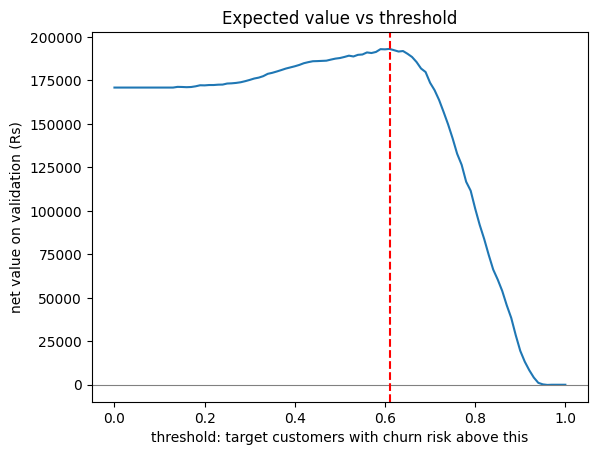

In [10]:
OFFER_COST = 100       # Rs spent on each customer who gets an offer
CUSTOMER_VALUE = 800   # Rs profit kept if a would-be churner stays
SAVE_RATE = 0.20       # share of would-be churners the offer actually keeps

churn_model = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                            subsample=0.8, eval_metric="logloss", random_state=0).fit(tr[features], tr["churn"])
pv = churn_model.predict_proba(va[features])[:, 1]
yv = va["churn"].values

def net_value(probs, y, threshold):
    target = probs >= threshold
    gain = np.where(y == 1, SAVE_RATE * CUSTOMER_VALUE - OFFER_COST, -OFFER_COST)
    return gain[target].sum()

thresholds = np.linspace(0, 1, 101)
values = [net_value(pv, yv, t) for t in thresholds]
best_i = int(np.argmax(values))

print("target nobody: Rs 0")
print("target everyone: Rs", round(net_value(pv, yv, 0)))
print("best threshold:", round(thresholds[best_i], 2), "| net value: Rs", round(values[best_i]),
      "| customers targeted:", int((pv >= thresholds[best_i]).sum()), "of", len(pv))

plt.plot(thresholds, values)
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(thresholds[best_i], color="red", linestyle="--")
plt.xlabel("threshold: target customers with churn risk above this")
plt.ylabel("net value on validation (Rs)")
plt.title("Expected value vs threshold")
plt.show()

## 8. Test result (scored once, threshold fixed from validation)

In [11]:
te = snap_test2[snap_test2["n_reviews"] >= 5]
pt = churn_model.predict_proba(te[features])[:, 1]
yt = te["churn"].values
best_t = thresholds[best_i]

print("test customers:", len(te), "| churn rate:", round(yt.mean(), 3))
print("target nobody: Rs 0")
print("target everyone: Rs", round(net_value(pt, yt, 0)))
print("model, threshold", round(best_t, 2), ": Rs", round(net_value(pt, yt, best_t)),
      "| targeted:", int((pt >= best_t).sum()), "of", len(pt))
print("test AUC:", round(roc_auc_score(yt, pt), 3), " PR-AUC:", round(average_precision_score(yt, pt), 3))
print("confusion matrix at the chosen threshold [[stay, stay-but-offered],[churn-missed, churn-offered]]:")
print(confusion_matrix(yt, pt >= best_t))

test customers: 9203 | churn rate: 0.756
target nobody: Rs 0
target everyone: Rs 193620
model, threshold 0.61 : Rs 214680 | targeted: 7586 of 9203
test AUC: 0.674  PR-AUC: 0.852
confusion matrix at the chosen threshold [[stay, stay-but-offered],[churn-missed, churn-offered]]:
[[ 738 1503]
 [ 879 6083]]


## 9. How fragile are the rupee assumptions?

One assumption is changed at a time. For each scenario the threshold is picked on validation and scored on test.

In [12]:
def net_value_p(probs, y, threshold, cost, value, save):
    target = probs >= threshold
    gain = np.where(y == 1, save * value - cost, -cost)
    return gain[target].sum()

def run_scenario(cost, value, save):
    vals = [net_value_p(pv, yv, t, cost, value, save) for t in thresholds]
    t_best = thresholds[int(np.argmax(vals))]
    everyone = net_value_p(pt, yt, 0, cost, value, save)
    model = net_value_p(pt, yt, t_best, cost, value, save)
    return t_best, everyone, model

base = dict(cost=100, value=800, save=0.2)
for k, options in [("cost", [50, 100, 200, 400]), ("value", [400, 800, 1600]), ("save", [0.1, 0.2, 0.3])]:
    for o in options:
        s = {**base, k: o}
        t_best, everyone, model = run_scenario(**s)
        print(s, "| threshold", round(t_best, 2), "| everyone Rs", round(everyone),
              "| model Rs", round(model), "| model minus everyone Rs", round(model - everyone))

{'cost': 50, 'value': 800, 'save': 0.2} | threshold 0.3 | everyone Rs 653770 | model Rs 655970 | model minus everyone Rs 2200
{'cost': 100, 'value': 800, 'save': 0.2} | threshold 0.61 | everyone Rs 193620 | model Rs 214680 | model minus everyone Rs 21060
{'cost': 200, 'value': 800, 'save': 0.2} | threshold 0.97 | everyone Rs -726680 | model Rs 0 | model minus everyone Rs 726680
{'cost': 400, 'value': 800, 'save': 0.2} | threshold 0.97 | everyone Rs -2567280 | model Rs 0 | model minus everyone Rs 2567280
{'cost': 100, 'value': 400, 'save': 0.2} | threshold 0.97 | everyone Rs -363340 | model Rs 0 | model minus everyone Rs 363340
{'cost': 100, 'value': 800, 'save': 0.2} | threshold 0.61 | everyone Rs 193620 | model Rs 214680 | model minus everyone Rs 21060
{'cost': 100, 'value': 1600, 'save': 0.2} | threshold 0.3 | everyone Rs 1307540 | model Rs 1311940 | model minus everyone Rs 4400
{'cost': 100, 'value': 800, 'save': 0.1} | threshold 0.97 | everyone Rs -363340 | model Rs 0 | model minus

## Summary

- **Leakage found and fixed:** the 5-core filter guarantees that users with fewer than 5 earlier reviews review again later. Their churn rate was about 0.47 to 0.50 against about 0.74 to 0.75 for everyone else. Only users with 5 or more reviews before the cutoff are used.
- **Accuracy is the wrong metric here:** always predicting churn is already about 75% accurate, and the chosen threshold is slightly below that on accuracy while still earning more money.
- **The rupee result depends on the assumptions:** the model's advantage over blanket offers is large only in a middle band of economics. When offers cost more than they can return, the best policy is to send none.
- **Limits:** reviews stand in for purchases, users in this dataset already have 5 or more reviews overall, and AUC is modest because review timing is a weak signal.